In [58]:
### tools
from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper

In [59]:
api_wrapper_arxiv=ArxivAPIWrapper(top_k_results=2, doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv, description="Query arxiv papers")
print(arxiv.name)

arxiv


In [60]:
api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1, doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.name

'wikipedia'

In [61]:
from dotenv import load_dotenv
load_dotenv()

import os

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [62]:
## Tavily Search Tool
from langchain_tavily import TavilySearch

tavily = TavilySearch(max_results=2)

In [63]:
tavily.invoke("Provide me the recent Ai news")

{'query': 'Provide me the recent Ai news',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.youtube.com/watch?v=eDiQNFa-zYg&vl=en-US',
   'title': 'AI News: The Only 6 Stories Worth Knowing This Week',
   'content': "# AI News: The Only 6 Stories Worth Knowing This Week\n## Channel: Matt Wolfe (verified)\n1.03M subscribers\n2.3K likes\n\n### Description\n134,238 views\nPosted: 2026-10-30\nCheck out Warp Factories here: \n\nThis week’s biggest AI news: OpenAI’s GPT-6.1 Terra brings faster computer use at a lower API cost, and Google’s Genie 4 brings real-time AI worlds to life. We’re also covering Gemini 4 Carbon, Kimi K3.1 Pro, and Anthropic’s IPO filing.\n\nSharing the latest news and advancements in AI [...] ### Chapters\n[0:00] Anthropic's $2 Trillion IPO\n[6:17] Warp Factories (Sponsor)\n[7:23] OpenAI's GPT-6.1 Tera\n[12:00] Google's Gemini 4 Carbon\n[13:39] Kimi K3.1 Pro: Powerful Open-Weight AI\n[18:07] Testing Google's Genie 4 World

In [64]:
## combine all these tools in the list
tools=[arxiv, wiki, tavily]

In [65]:
## Initialize the LLM model
from langchain_groq import ChatGroq

llm=ChatGroq(model="qwen/qwen3.8-27b")

In [66]:
llm.invoke("What is AI")

AIMessage(content='**AI (Artificial Intelligence)** is a branch of computer science focused on creating systems capable of performing tasks that typically require human intelligence.\n\n### Core Concepts\n*   **Definition**: AI refers to the simulation of human cognitive processes by machines, particularly computer systems.\n*   **Goal**: To build machines that can think, learn, reason, and solve problems autonomously.\n*   **Scope**: It encompasses a wide range of technologies, from simple rule-based systems to complex deep learning models.\n\n### Key Types of AI\n1. **Narrow AI (Weak AI)**: Designed for a specific task (e.g., voice assistants like Siri, recommendation systems like Netflix, or chess-playing programs like Deep Blue). This is the most common form of AI today.\n2. **General AI (Strong AI)**: Hypothetical AI that would possess human-level cognitive abilities across any domain. This does not currently exist.\n3. **Super AI**: A theoretical form of AI that would surpass hum

In [67]:
llm_with_tools=llm.bind_tools(tools=tools)

In [68]:
## Excute this call
llm_with_tools.invoke("What is samkhaya philosopy?")

AIMessage(content='Sāṃkhya (Sanskrit: संख्या) is one of the six **Astika** (orthodox) schools of Indian philosophy. It is one of the oldest and most influential philosophical systems in India, founding the framework for much of classical Indian thought.\n\nHere is a breakdown of Sāṃkhya philosophy:\n\n### 1. Core Ontology: Dualism\nSāṃkhya is fundamentally a **dualist** system. It posits that the universe consists of two fundamental, uncreated, and eternal realities:\n\n*   **Purusha (The Self/Soul):**\n    *   Pure consciousness.\n    *   Inert, passive, and unchanging.\n    *   It is the witness, not the actor.\n    *   There are many Purushas (one for each individual soul).\n*   **Prakriti (Matter/Nature):**\n    *   The material principle.\n    *   Active, dynamic, and constantly changing.\n    *   It is unconscious, blind, and operates without a purpose.\n    *   There is only one universal Prakriti.\n\n### 2. The Problem: Why does the universe exist?\nSāṃkhya does **not** believe

Workflow

In [69]:
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage ## Human or Ai message
from typing import Annotated ##labelling
from langgraph.graph.message import add_messages ## Reducers in Langgharph

In [70]:
class State(TypedDict):
    messages : Annotated[list[AnyMessage], add_messages]
    

builder = StateGraph(State)    

In [71]:
### Entire Chatbot with LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


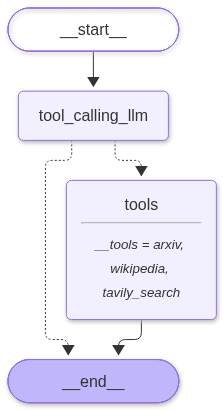

In [72]:
## node defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))   


## adding edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #If the letest message (result) from assistant is a tool call -> tool_codition routes to tools
    #If the letest message (result) from assistant is a not tool call -> tool_codition routes to END
    tools_condition
)
builder.add_edge("tools", END)

graph = builder.compile()

##disply
display(Image(graph.get_graph().draw_mermaid_png()))


In [73]:
import arxiv
print(arxiv.__version__)

4.1.0


In [74]:
messages=  graph.invoke({"messages":"Hi my name is latika"})
for m in messages['messages']:
    m.pretty_print()

KeyboardInterrupt: 

In [79]:
messages=  graph.invoke({"messages":"Hi my name is latika and Search the web for the latest news about Ratan Tata?"})
for m in messages['messages']:
    m.pretty_print()

    # Check if the AI message triggered any tool calls
    if hasattr(m, "tool_calls") and m.tool_calls:
        for tool_call in m.tool_calls:
            print(f"\n>>> TOOL CALLED: {tool_call['name']}")
            print(f">>> ARGUMENTS:   {tool_call['args']}\n")

================================ Human Message =================================

Hi my name is latika and Search the web for the latest news about Ratan Tata?
================================== Ai Message ==================================

I'm sorry, but I don't have the capability to search the web for real-time news. My knowledge is based on information available up until early 2025, and I cannot access live news updates.

However, I can share that **Ratan Tata** passed away on **October 7, 2024**, at the age of 86 in Mumbai, India. He was the former chairman of the Tata Sons group and was widely respected for his leadership, integrity, and contributions to Indian industry and philanthropy.

You can check the latest news about him on:
- Major news websites like **Reuters**, **BBC**, **The Hindu**, or **NDTV**
- Social media platforms like **X (Twitter)** or **LinkedIn**
- News aggregators like **Google News** or **Flipboard**

Would you like me to look up any specific information a